## WORKING WITH A NEW DATASET LAST NOTEBOOK COULDN'T DELIVER.

In [1]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('./student2.csv', sep=';')
df

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,MS,M,20,U,LE3,A,2,2,services,services,...,5,5,4,4,5,4,11,9,9,9
391,MS,M,17,U,LE3,T,3,1,services,services,...,2,4,5,3,4,2,3,14,16,16
392,MS,M,21,R,GT3,T,1,1,other,other,...,5,5,3,3,3,3,3,10,8,7
393,MS,M,18,R,LE3,T,3,2,services,other,...,4,4,1,3,4,5,0,11,12,10


In [3]:
df['studytime']

0      2
1      2
2      2
3      3
4      2
      ..
390    2
391    1
392    1
393    1
394    1
Name: studytime, Length: 395, dtype: int64

In [4]:
X = df.drop(columns=['G3'])
y = df['G3']

category_columns = X.select_dtypes(include=['object', 'str', 'category']).columns.tolist()

category_columns

['school',
 'sex',
 'address',
 'famsize',
 'Pstatus',
 'Mjob',
 'Fjob',
 'reason',
 'guardian',
 'schoolsup',
 'famsup',
 'paid',
 'activities',
 'nursery',
 'higher',
 'internet',
 'romantic']

In [5]:

category_columns = X.select_dtypes(
    include=["object", "category", "str"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["number"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore"),
            category_columns
        ),
        (
            "numeric",
            "passthrough",
            numerical_columns
        )
    ],
    remainder="drop"
)


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
param_grid = {
    'regressor__n_estimators': [100, 200, 300],
    'regressor__max_depth': [None, 5, 10, 20],
    'regressor__min_samples_split': [2, 5, 10],
    'regressor__min_samples_leaf': [6, 15, 30],
    # 'regressor__max_features': [1.0, 'sqrt', 0.5]
}

In [8]:
def train_model(X_train, X_test, y_train, y_test):

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor())
    ])

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        cv=5,
        scoring='neg_mean_absolute_error',
        n_jobs=-1,
        verbose=1
    )

    grid_search.fit(X_train, y_train)

    best_model = grid_search.best_estimator_
    prediction = grid_search.predict(X_test)

    mae = mean_absolute_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)

    print('Best Parameters:', grid_search.best_params_)
    print(f'Best Cross Validation MAE: {-grid_search.best_score_:.2f}')
    print(f'Test MAE: {mae:.2f}')
    print(f'Test RMSE: {mse ** 0.5:.2f}')

    return best_model, grid_search

In [9]:
model, search = train_model(X_train, X_test, y_train, y_test)

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best Parameters: {'regressor__max_depth': 10, 'regressor__min_samples_leaf': 6, 'regressor__min_samples_split': 2, 'regressor__n_estimators': 200}
Best Cross Validation MAE: 0.98
Test MAE: 1.15
Test RMSE: 1.88


In [10]:
model_pred = model.predict(X_test)

results = pd.DataFrame({
    'G3': y_test, 'Predicted G3': model_pred.round(2)
})

results.head(15)

,G3,Predicted G3
78,10,8.11
371,12,11.80
248,5,5.35
55,10,9.39
390,9,8.89
223,13,12.84
42,18,18.24
234,6,7.20
316,0,5.72
116,14,13.19


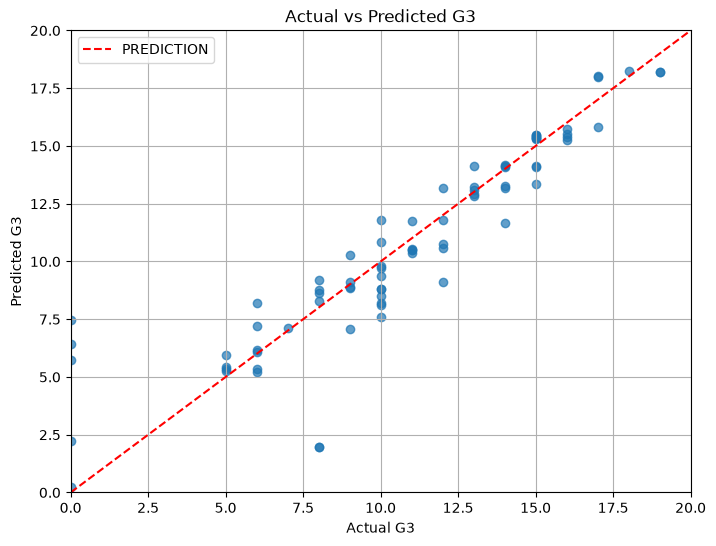

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, model_pred, alpha=0.7)

plt.plot([0, 20], [0, 20], 'r--', label='PREDICTION')

plt.xlabel('Actual G3')
plt.ylabel('Predicted G3')
plt.title('Actual vs Predicted G3')
plt.legend()
plt.grid(True)

plt.xlim(0, 20)
plt.ylim(0, 20)

plt.show()

### SAVE THE MODEL

In [12]:
import joblib

joblib.dump(model, 'student_performance_model.pkl')

['student_performance_model.pkl']

In [13]:
import json

columns = list(X_train.columns)

with open('columns.json', 'w') as f:
    json.dump(columns, f, indent=4)

print(columns)

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [14]:
template = df[
    (df['Mjob'] == 'teacher') & (df['Fjob'] == 'teacher')
].iloc[0]

template

school             GP
sex                 M
age                16
address             U
famsize           GT3
Pstatus             T
Medu                4
Fedu                4
Mjob          teacher
Fjob          teacher
reason           home
guardian       mother
traveltime          1
studytime           2
failures            0
schoolsup          no
famsup            yes
paid              yes
activities        yes
nursery           yes
higher            yes
internet          yes
romantic          yes
famrel              4
freetime            4
goout               5
Dalc                5
Walc                5
health              5
absences           16
G1                 10
G2                 12
G3                 11
Name: 29, dtype: object

In [15]:
template_data = template.to_dict()

with open('template.json', 'w') as f:
    json.dump(template_data, f, indent=4)

print(template_data)

{'school': 'GP', 'sex': 'M', 'age': 16, 'address': 'U', 'famsize': 'GT3', 'Pstatus': 'T', 'Medu': 4, 'Fedu': 4, 'Mjob': 'teacher', 'Fjob': 'teacher', 'reason': 'home', 'guardian': 'mother', 'traveltime': 1, 'studytime': 2, 'failures': 0, 'schoolsup': 'no', 'famsup': 'yes', 'paid': 'yes', 'activities': 'yes', 'nursery': 'yes', 'higher': 'yes', 'internet': 'yes', 'romantic': 'yes', 'famrel': 4, 'freetime': 4, 'goout': 5, 'Dalc': 5, 'Walc': 5, 'health': 5, 'absences': 16, 'G1': 10, 'G2': 12, 'G3': 11}
